# Flare Energetics on 2M0508-21 - A simultaneous superflare-radio burst on a complex periodic variable

# Monochromatic filter approximation

v-band relative extra flux ratio post-flare: 3.2464000491715446
i-band relative extra flux ratio post-flare: 0.4955608380132644
Flux ratio v/i quiescence, observed: 0.097638936752675
Flux ratio v/i post flare, observed: 0.639628931022304
Delay of the v-band bin center wrt i-band modeled peak [min]: 9.292666670974965 min

Post-flare temperature:  5230.0 K
Emitting radius post-flare from observed color and fluxes [Rsun, Rstar]:  0.19869161203411045 solRad 0.4464980045710347
Emitting area post-flare from observed color and fluxes [Asun, Astar]:  0.03947835669271347 solRad2 0.19936046808591573

Scenario 1.

Assumed constant temperature [K]:  5230.0 K
Area peak, post: 1.124097400718751e+18 m2 2.4011148702961923e+17 m2
Sanity check: area_post/area_peak = exp(-dtv/tau_d) 0.21360380948847607 0.21360380948847607
Emitting radius at the peak [Rsun, Rstar]:  0.4299075145578509 solRad 0.9660843023771931
Emitting area at the peak [Asun, Astar]:  0.1848204710733088 solRad2 0.9333188792996279
Peak lum

Text(0, 0.5, 'Luminosity (erg/s)')

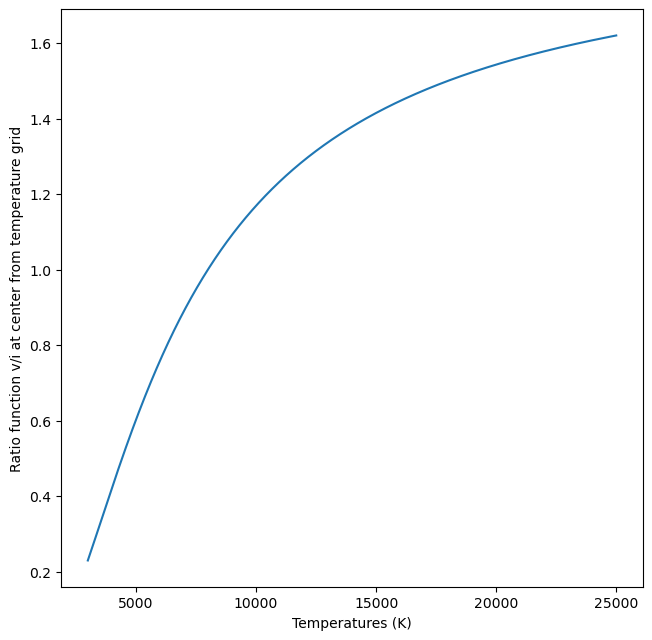

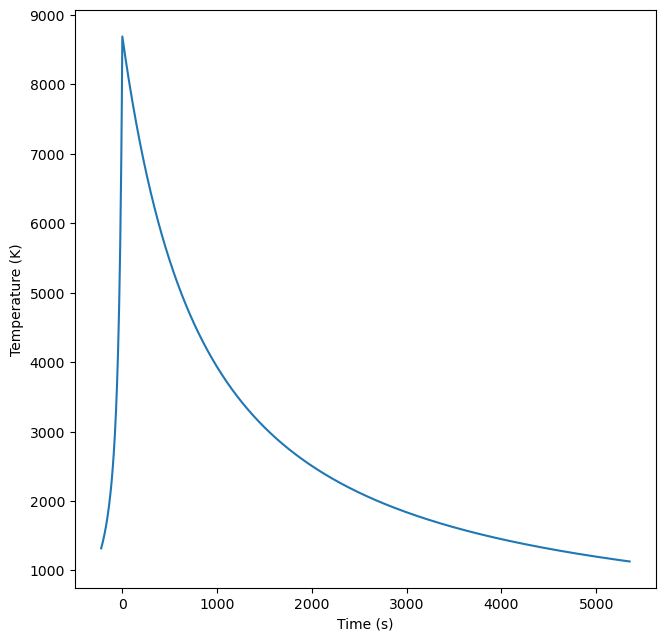

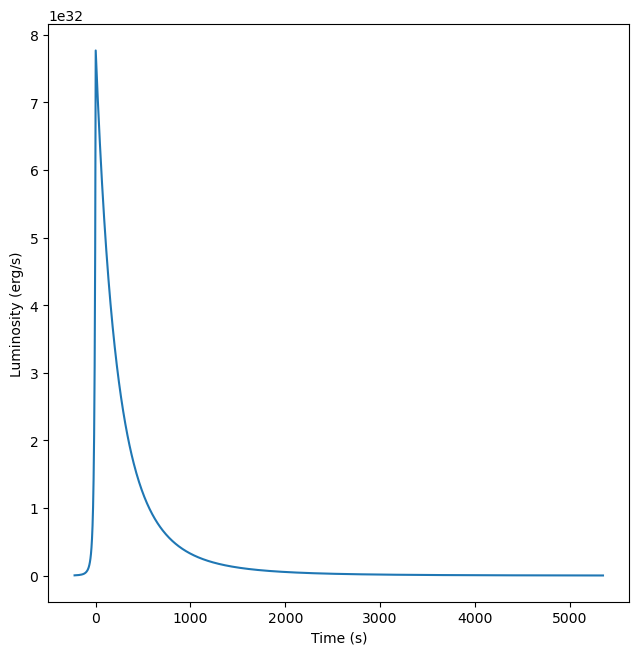

In [32]:
# import libraries
import mpmath
import numpy as np
import astropy.constants as cs 
import astropy.units as u 
import matplotlib.pyplot as plt 


# Distance of the system and radius of a single star
d = 48.3 * u.pc                  # distance [pc]
Rstar = 0.445 *u.R_sun            # Stellar radius in Solar radius (Bejar et al. in prep.)
# Bouma reported Rstar=0.8 Rsun, but considering a single star; M-R relations give Rstar = 0.22 Rsun, but this is young and inflated

# Central wavelengths and frequencies of the filters LCOGT # https://lco.global/observatory/instruments/filters/ 
lam_i_c = 7.545e-7 * u.m  # lambda of band i' [m] # SDSS 
lam_v_c = 5.448e-7 * u.m # lambda of band v  [m] # Johnson
nu_i_c = (cs.c/lam_i_c).to("Hz") 
nu_v_c = (cs.c/lam_v_c).to("Hz")

# Quiescent fluxes (consider 5-10% fluctuations)
mag_i_q = 12.316         # Magnitude in quiescence band i, SIMBAD, UCAC4
flux0 = 3.631e-23        # reference specific flux W/m2/Hz for mag=0, AB system
fluxs_i_q = flux0* 10**(-mag_i_q/2.5) *u.W/u.m**2 * 1/u.Hz  # specific flux [W/m2/Hz] CHECK CONVERSION!!! 
fluxs_v_q = 4.2* u.milliJansky    #mJy_to_SI   # specific flux [W/m2/Hz] from ASAS-SN data set, excluding two flare points, 4.22\pm0.16 mJy # no it 3.9 because the magnitude is in vega ref system
fluxs_v_q = fluxs_v_q.to("W / (m^2 Hz)")
ratio_vi_q = fluxs_v_q/fluxs_i_q 

# Amount of extra flux in the flare in v-band (post-flare) and i-band (modelled peak)
# The values are the relative extra flux, Af = (flux - Aq)/Aq, where Aq is the quiescence
vpost = 0.46316              # Relative flux v-band 0.46316 
vbase = 0.109071212           # Base flux v-band, taking the point 10 minutes before the flare
vpost_rel = (vpost - vbase)/vbase  
ipeak_rel = 2.32                  # Peak of the i-band extra flux, from the double exponential model exp-exp 

# conversion of extraflux into physical units [W/m2/Hz]
fluxs_v_post = vpost_rel*fluxs_v_q 
fluxs_i_peak = ipeak_rel*fluxs_i_q 
lums_i_peak = fluxs_i_peak*4.*np.pi*(d.to("m"))**2   # observed specific luminosity in i-band at peak [W/Hz] 

# Timing 
tp_opt = 17 * u.s                  # Modeled i-band peak time, with respect to the reference time [s] - Exp-exp model
time_ref = 60560.59609000 * u.day     # Reference time (central time of the radio bin with highest flux) [MJD]
time_v = 60560.60274  * u.day        # Central time of post-flare sole data point [MJD]
dtv = (time_v - time_ref).to("s") - tp_opt # Delay from the i-band peak time to the v-band observation [s] 


# i-band flux coincident with v-band flux
taud = 361.2 * u.s                  # decay timescale of the flare, modeled from i-band (expexp model) [s]
taur = 18 * u.s                     # rise timescale of the flare, modeled from i-band (expexp model) [s]

fluxs_i_post = fluxs_i_peak*np.exp(-dtv/taud)  # Specific flux in i-band at the time of v-band observation 
lums_i_post = fluxs_i_post*4.*np.pi*(d.to("m"))**2   # specific luminosity post-flare [W/Hz] 
ipost_rel = fluxs_i_post/fluxs_i_q             # Relative extra flux in i-band at the time of v-band observation 
ratio_vi_post = fluxs_v_post/fluxs_i_post      # v/i specific flux ratio at the time of v-band observation 

print("v-band relative extra flux ratio post-flare:",vpost_rel)
print("i-band relative extra flux ratio post-flare:",ipost_rel)
print("Flux ratio v/i quiescence, observed:",ratio_vi_q)
print("Flux ratio v/i post flare, observed:",ratio_vi_post)
print("Delay of the v-band bin center wrt i-band modeled peak [min]:",dtv.to("min"))


# blackbody model with central frequency as input
def blackbody_nu_c(nu, T): 
    pre_factor = 2*cs.h.value/cs.c.value**2 * nu.value**3 
    exp_factor = 1/(np.exp(cs.h.value * nu.value  /(cs.k_B.value*T.value) )-1)
    return pre_factor * exp_factor # fake convolution with response

# blackbody ratio function 
ratio_vi_color_c = []
# temperature grid
temperatures = np.arange(3000,25000,10) * u.Kelvin

# calculate the ratio
for temp in temperatures: 
    ratio_vi_color_c.append(blackbody_nu_c(nu_v_c, temp)/blackbody_nu_c(nu_i_c, temp))  

# helper to get temperature out of ratio
def find_nearest(array1, array2, value):
    array1 = np.asarray(array1)
    idx = np.abs(array1 - value).argmin()
    nearest = array1[idx]
    pct_diff = np.abs(value - nearest) / np.abs(nearest) * 100 if nearest != 0 else np.inf
    return array2[idx], idx, pct_diff

# get post temperature and index;  Temperature at the post-flare to match the observed color [K]
temp_post,idx, diff_ratio  = find_nearest(np.asarray(ratio_vi_color_c), temperatures.value, ratio_vi_post)
temp_post = temp_post * u.Kelvin

# plot response in wavelength, freqency
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7.5, 7.5))

ax.plot(temperatures, ratio_vi_color_c)
ax.set_xlabel("Temperatures (K)")
ax.set_ylabel("Ratio function v/i at center from temperature grid")

# take float because mpmath gives back mpf object
bl_v_post = 2*cs.h*nu_v_c.to("1/s")**3/cs.c**2/(float(mpmath.exp(cs.h.value*nu_v_c.value/(cs.k_B.value*temp_post.value)))-1)     # spectral radiance [W/sr/m^2/Hz] 
bl_i_post = 2*cs.h*nu_i_c.to("1/s")**3/cs.c**2/(float(mpmath.exp(cs.h.value*nu_i_c.value/(cs.k_B.value*temp_post.value)))-1)     # spectral radiance [W/sr/m^2/Hz] 

area_post = (lums_i_post/bl_i_post).to("m^2")              # Emitting area post-flare [m2] 
R_post = np.sqrt(area_post/(4*np.pi))/cs.R_sun  * u.Rsun     # Emitting area post-flare [Rsun] / more emitting fractional radius
print()
print("Post-flare temperature: ",temp_post)
#print("Sanity check: expected extra flux ratio v/i (absolute, to be compared with above, and normalized): ")
#print(bl_v_post/bl_i_post,bl_v_post/bl_i_post/ratio_vi_q)
print("Emitting radius post-flare from observed color and fluxes [Rsun, Rstar]: ",R_post,R_post/Rstar)
print("Emitting area post-flare from observed color and fluxes [Asun, Astar]: ",R_post**2,(R_post/Rstar)**2)

# Spectral assumptions with constant effective temperature, so that R \sim exp(-t/2*taud)
print()
print("Scenario 1.")


for m in range(1,2):
    
    # Multiply the inferred post-flare temperature by a factor m, if one wants to test different temperatures
    temp = temp_post*m
    bl_i = 2*cs.h*nu_i_c**3/cs.c**2/float((mpmath.exp(cs.h.value*nu_i_c.value/(cs.k_B.value*temp.value))-1))     # spectral radiance [W/sr/m^2/Hz]
    bl_v = 2*cs.h*nu_v_c**3/cs.c**2/float((mpmath.exp(cs.h.value*nu_v_c.value/(cs.k_B.value*temp.value))-1) )    # spectral radiance [W/sr/m^2/Hz]
    area_peak = (lums_i_peak/bl_i).to("m^2")                    # Emitting area at peak [m2]
    R_peak = np.sqrt(area_peak/(4*np.pi))/cs.R_sun  * u.Rsun    # Emitting area in Solar radius at the peak
    lum_peak_cgs = (area_peak*temp**4*cs.sigma_sb).to("erg/s")   # bolometric blackbody luminosity at peak of the flare [erg/s]
    energy_cgs = lum_peak_cgs*(taur+taud)                # bolometric blackbody energy release during the whole flare [erg] # exact integral of model


    print()
    print("Assumed constant temperature [K]: ",temp)
    print("Area peak, post:",area_peak,area_post)
    print("Sanity check: area_post/area_peak = exp(-dtv/tau_d)",area_post/area_peak,np.exp(-dtv/taud))
    print("Emitting radius at the peak [Rsun, Rstar]: ",R_peak,R_peak/Rstar)
    print("Emitting area at the peak [Asun, Astar]: ",R_peak**2,(R_peak/Rstar)**2)
    print("Peak luminosity in erg/s, energy in erg: ",lum_peak_cgs,energy_cgs)

    
# Event rate of events with this or larger bolometric energy, from Konijn+ 2026, Yang & Liu 2019
rate_yr = 7e40/1.13*energy_cgs.value**(-1.13)   # event rate above that energy [1/year]
print()
print("Rate of event above that energy per year (Yang & Liu 2019): ",rate_yr)


# Spectral assumptions with constant area, T evolves in time according to Planck's law, and so does L(t)
area = area_post
print()
print("Scenario 2.")
print("Assumed constant radius [Rstar]: ",R_post/Rstar)
print("Assumed constant area [Astar]: ",(R_post/Rstar)**2)
print()
print()

# define time decay grid / relevant only because the rise phase contributes little to bolometric energy
energy, temperature_evolution, luminosity = [], [], [] # for plotting
tmin = -0.4*dtv # minimum time [s], negative to include the rise time
tmax = tmin + 10*dtv # maximum time [s]
Nt = 1001 # sampling points (odd to get the value t=0, peak)
time_grid = np.linspace(tmin, tmax, Nt) # time [s] for plotting, t=0 being the peak
dt = (tmax-tmin)/(Nt-1)

# loop over time grid 
for m in range(0,Nt):
  tc = time_grid[m] 
  if (tc > 0):
    lums_i_cont =  lums_i_peak * np.exp(-tc/taud)    # decay phase
  else:
    lums_i_cont =  lums_i_peak * np.exp(tc/taur)   # rise phase
  bl_i_cont = lums_i_cont/area
  # solve for temperature analytically from Planck's law
  expfac = np.log(1 + 2*cs.h*nu_i_c**3/(bl_i_cont*cs.c**2))
  prefac = cs.h*nu_i_c/cs.k_B
  temp_cont = prefac/expfac # temperature [K] at tc 
  lum_cont = (area*temp_cont**4*cs.sigma_sb).to("erg/s") # bolometric luminosity [erg/s]
  # add flare energy and temperature at t to energy and temperature array
  energy.append((dt.to(u.s) * lum_cont).to_value(u.erg))
  luminosity.append(lum_cont.value)
  temperature_evolution.append(temp_cont.value)
  if (np.abs(tc) < 1e-3*u.s):
    lum_peak_cgs = lum_cont
    temp_peak = temp_cont

# sum to obtain the total bolometric energy
energy_cgs2 = np.sum(energy) * u.erg # bolometric energy in scenario 2 [erg]
print("Peak luminosity, energy: ",lum_peak_cgs,energy_cgs2)

# Event rate of events with this or larger bolometric energy
rate_yr = 7e40/1.13*energy_cgs2.value**(-1.13)   # event rate above that energy [1/year], from Konijn+ 2026, Yang & Liu 2019
print()
print("Rate of event above that energy per year (Yang & Liu 2019): ",rate_yr)

# plot temperature evolution
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7.5, 7.5))

ax.plot(time_grid, np.asarray(temperature_evolution))
ax.set_xlabel("Time (s)")
ax.set_ylabel("Temperature (K)")

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7.5, 7.5))

ax.plot(time_grid, np.asarray(luminosity))
ax.set_xlabel("Time (s)")
ax.set_ylabel("Luminosity (erg/s)")

## Flux Integration over the filters

Observed ratio v/i:  0.639628931022304
Post-flare temperature [K] in monochromatic assumption or with filter:  5230.0 K 5380.0 K
Post-flare area [K] in monochromatic assumption or with filter:  2.4011148702961923e+17 m2 2.178656501681827e+17 m2
Scenario 1: constant temperature.
Assumed constant temperature [K]:  5380.0 K
Area peak, post: 1.124097400718751e+18 m2 2.4011148702961923e+17 m2
Sanity check: area_post/area_peak = exp(-dtv/tau_d) 0.2136038094884761 0.21360380948847607
Emitting radius at the peak [Rsun, Rstar]:  0.4299075145578509 solRad 0.9660843023771931
Emitting area at the peak [Asun, Astar]:  0.1848204710733088 solRad2 0.9333188792996279
Peak luminosity in erg/s, energy in erg:  5.340043353448509e+32 erg / s 2.0249444396276746e+35 erg

Scenario 2 Fully integrated.
Assumed flare area:  2.178656501681827e+17 m2
Peak temperature Guess from Post-flare ratio:  8939.93411841011 Hz K s


Peak luminosity, energy:  8.222379882952108e+32 erg / s 2.3641315250661605e+35 erg


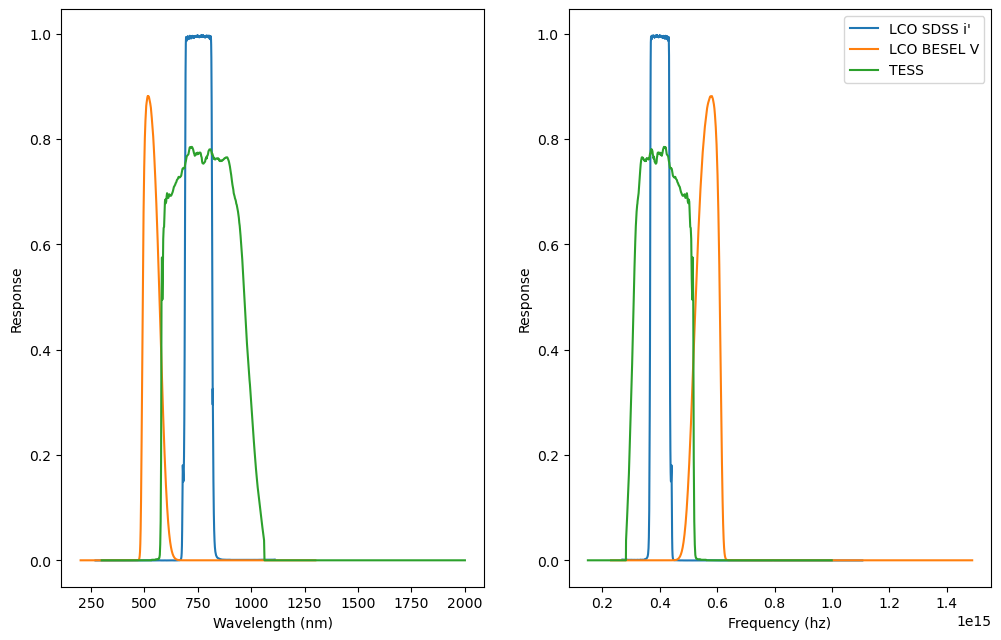

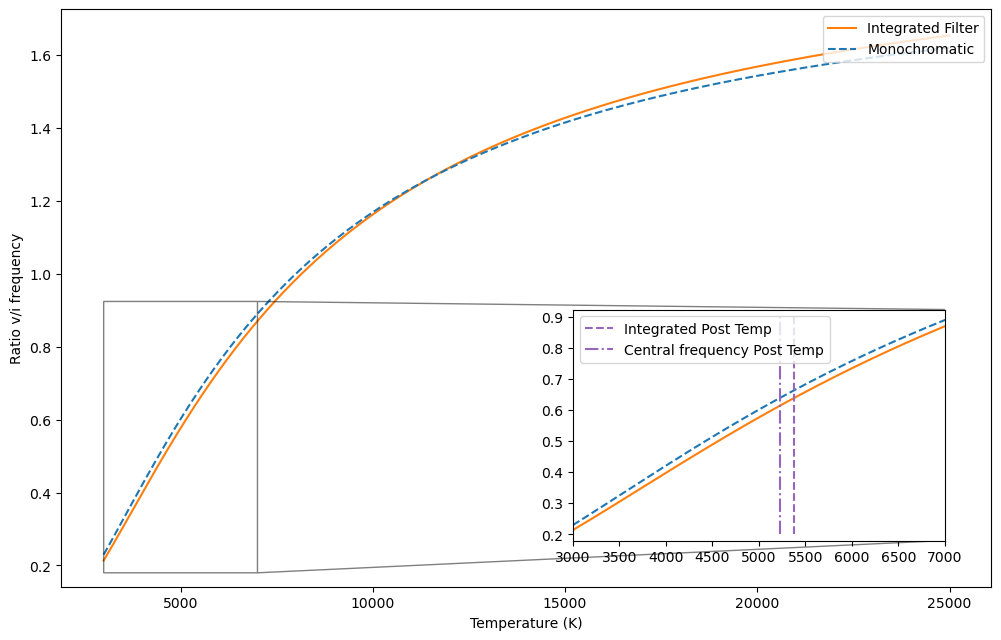

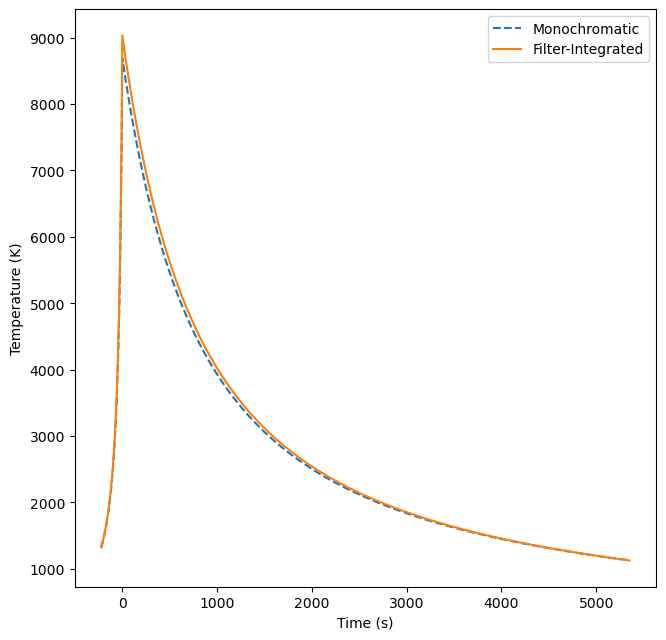

In [33]:
# Integrated flux over filters instead of using the central wavelengths as above

import pandas as pd 
from scipy import integrate 
import astropy.constants as cs 
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
import numpy as np

# Response functions: color in V and i' and tess
# load response function

i_resp = pd.read_csv(
    "sdss.ip.txt",
    skiprows=7,
    sep='\s+',
    names=["wav", "resp"],
    header=None,
    comment="#"
    )
wav_i, resp_i = i_resp.wav.values * u.nanometer, i_resp.resp.values

v_resp = pd.read_csv(
    "bssl-vx-022.txt",
    skiprows=7,
    sep='\s+',
    names=["wav", "resp"],
    header=None,
    comment="#"
    )
wav_v, resp_v = v_resp.wav.values * u.nanometer, v_resp.resp.values

tess_resp = pd.read_csv("tess-response-function-v2.0.csv", 
    skiprows=7, 
    names=["wav", "resp"], 
    header=None)
wav_tess, resp_tess = tess_resp.wav.values * u.nanometer, tess_resp.resp.values

# calculate frequencies
nu_i = cs.c/(wav_i.to("m"))
nu_v = cs.c/(wav_v.to("m"))
nu_tess = cs.c/(wav_tess.to("m"))

# plot response in wavelength, freqency
fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(12, 7.5))

ax[0].plot(wav_i, resp_i, label = "LCO SDSS i'")
ax[0].plot(wav_v, resp_v, label ="LCO BESEL V")
ax[0].plot(wav_tess, resp_tess, label = "TESS") 
ax[0].set_xlabel("Wavelength (nm)")
ax[0].set_ylabel("Response")

ax[1].plot(nu_i, resp_i, label = "LCO SDSS i'")
ax[1].plot(nu_v, resp_v, label ="LCO BESEL V")
ax[1].plot(nu_tess, resp_tess, label = "TESS") 
ax[1].set_xlabel("Frequency (hz)")
ax[1].set_ylabel("Response")

plt.legend()

# integration functions 

# blackbody integral over frequency, weighted by the normalised response
def blackbody_filter(nu, T ,response):
    y1 = blackbody_nu(nu, T, response) 
    norm = integrate.trapezoid(np.flip(response), x=np.flip(nu))
    return integrate.trapezoid(np.flip(y1), x=np.flip(nu))/norm
# flip because otherwise integral is negative due to invert form of frequency

# blackbody integral over wavelength, weighted by the normalised response
def blackbody_filterw(wavelength, T, response):
    y1 = blackbodyw(wavelength, T, response)
    norm = integrate.trapezoid(response, x=wavelength)
    return integrate.trapezoid(y1, x=wavelength)

# black body model frequency with protection from numpy overflow
def blackbody_nu(nu, T, response):
    x = cs.h * nu / (cs.k_B * T)
    with np.errstate(over="ignore"):
        b = 2 * cs.h * nu**3 / (cs.c**2 * np.expm1(x))
    return b * response

# black body model wavelength, without protection from numpy overflow
def blackbodyw(wavelength, temperature, response): 
    pre_factor = 2* (cs.h * cs.c**2)/ wavelength**5 
    exponential_factor = 1. /(np.exp((cs.h*cs.c) / (wavelength * cs.k_B * temperature))-1)
    return pre_factor * exponential_factor * response #fake convolution with response


# calulate ratio function when the filters response is considered
R_vi = []
for temp in temperatures: 
    R_vi.append(blackbody_filter(nu_v, temp, resp_v)/blackbody_filter(nu_i, temp, resp_i))

# Plot temeprature ratios 
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(12, 7.5))

ax.plot(temperatures, R_vi, color="tab:orange", label="Integrated Filter")
ax.plot(temperatures, ratio_vi_color_c, linestyle="--", label="Monochromatic")
ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Ratio v/i frequency")
ax.legend(loc="upper right")

# Inset in the lower right corner
axins = ax.inset_axes([0.55, 0.08, 0.4, 0.4])  # [x0, y0, width, height] in axes coords
axins.plot(temperatures, R_vi, color="tab:orange")
axins.plot(temperatures, ratio_vi_color_c, linestyle="--")

x1, x2 = 3000, 7000
axins.set_xlim(x1, x2)

# Auto-scale y-limits to the data within the zoom region
T = np.asarray(temperatures)
mask = (T >= x1) & (T <= x2)
y_all = np.concatenate([np.asarray(R_vi)[mask], np.asarray(ratio_vi_color_c)[mask]])
pad = 0.05 * (y_all.max() - y_all.min())
axins.set_ylim(y_all.min() - pad, y_all.max() + pad)
axins.vlines(x=temp_post_int.value, ymin=0.2, ymax=0.9, linestyle="--", color="tab:purple", label="Integrated Post Temp")
axins.vlines(x=temp_post.value, ymin=0.2, ymax=0.9, linestyle="-.", color="tab:purple", label ="Central frequency Post Temp")
axins.legend()

ax.indicate_inset_zoom(axins, edgecolor="black")


# find post peak temperature
print("Observed ratio v/i: ",ratio_vi_post)
temp_post_int, idx, diff_ratio_int = find_nearest(R_vi, temperatures, ratio_vi_post)
# Corresponding area
area_post_int =  (lums_i_post / (blackbody_filter(nu_i, temp_post_int, resp_i)) ).to("m^2")

# Scale to obtain peak temperature 
ratio_c_int = temp_post_int/temp_post
temp_peak_int = temp_peak * ratio_c_int
print("Post-flare temperature [K] in monochromatic assumption or with filter: ",temp_post,temp_post_int)
print("Post-flare area [K] in monochromatic assumption or with filter: ",area_post,area_post_int)

print("Scenario 1: constant temperature.")

for m in range(1,2):
    
    temp = temp_post_int*m
    bl_i_int = blackbody_filter(nu_i, temp, resp_i)     # spectral radiance [W/sr/m^2/Hz]
    bl_v_int = blackbody_filter(nu_v, temp, resp_v)     # spectral radiance [W/sr/m^2/Hz]
    area_peak_int = (lums_i_peak/bl_i_int).to("m^2")                    # Emitting area at peak [m2]
    R_peak_int = np.sqrt(area_peak/(4*np.pi))/cs.R_sun  * u.Rsun    # Emitting area in Solar radius at the peak
    lum_peak_cgs_int = (area_peak*temp**4*cs.sigma_sb).to("erg/s")   # bolometric blackbody luminosity at peak of the flare [erg/s]
    energy_cgs_int = lum_peak_cgs_int*(taur+taud)                # bolometric blackbody energy release during the whole flare [erg] # exact integral of model

    print("Assumed constant temperature [K]: ",temp)
    print("Area peak, post:",area_peak,area_post)
    print("Sanity check: area_post/area_peak = exp(-dtv/tau_d)",area_post_int/area_peak_int,np.exp(-dtv/taud))
    print("Emitting radius at the peak [Rsun, Rstar]: ",R_peak_int,R_peak_int/Rstar)
    print("Emitting area at the peak [Asun, Astar]: ",R_peak_int**2,(R_peak_int/Rstar)**2)
    print("Peak luminosity in erg/s, energy in erg: ",lum_peak_cgs_int,energy_cgs_int)


#### With constant Area need to implement a numerical solution for the temperature; 

area = area_post_int
print()
print("Scenario 2 Fully integrated.")
print("Assumed flare area: ", area_post_int)
print("Peak temperature Guess from Post-flare ratio: ",temp_peak_int)
print()
print()


# define time decay grid / relevant only because the rise phase contributes little to bolometric energy
energy_int, temperature_evolution_int, luminosity_int = [], [], [] # for plotting
tmin = -0.4*dtv # minimum time [s], negative to include the rise time
tmax = tmin + 10*dtv # maximum time [s]
Nt = 1001 # sampling points (odd to get the value t=0, peak)
time_grid = np.linspace(tmin, tmax, Nt) # time [s] for plotting, t=0 being the peak

from scipy.integrate import trapezoid
from scipy.optimize import brentq


# numerical temperature finder 
def find_temperature(bl_i_cont, m=None):
    target = bl_i_cont.value
    f = lambda T: blackbody_filter(nu_i, T * u.Kelvin, resp_i ).value - target
    try:
        return brentq(f, 1, 1e8) * u.K
    except ValueError:
        print(f"m={m}, target={target}, f(1)={f(1)}, f(1e8)={f(1e8)}")
        raise

# loop over time grid 
for m in range(0,Nt): 
    
  tc = time_grid[m] 
  if (tc > 0):
    lums_i_cont =  lums_i_peak * np.exp(-tc/taud)    # decay phase
  else:
    lums_i_cont =  lums_i_peak * np.exp(tc/taur)   # rise phase
  bl_i_cont = lums_i_cont/area

  # solve for temperature numerically
  temp_cont_int = find_temperature(bl_i_cont,m) # temperature [K] at t=t[m] 
  lum_cont_int = (area*temp_cont_int**4*cs.sigma_sb).to("erg/s") # bolometric luminosity [erg/s]
  # add flareenergy at t to energy array
  energy_int.append((dt.to(u.s) * lum_cont_int).to_value(u.erg))
  luminosity_int.append(lum_cont_int.value)
  temperature_evolution_int.append(temp_cont_int.value)
  if (np.abs(tc) < 1e-3*u.s):
    lum_peak_cgs_int = lum_cont_int
    temp_peak_int = temp_cont_int


# sum to obtain the total bolometric energy
energy_cgs_int = np.sum(energy_int) * u.erg # bolometric energy in szenario2 [erg]
print("Peak luminosity, energy: ",lum_peak_cgs_int,energy_cgs_int)

# plot temperature evolution
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7.5, 7.5))

ax.plot(time_grid, np.asarray(temperature_evolution), linestyle = "--", label = "Monochromatic")
ax.plot(time_grid, np.asarray(temperature_evolution_int),  label = "Filter-Integrated")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Temperature (K)")
ax.legend()

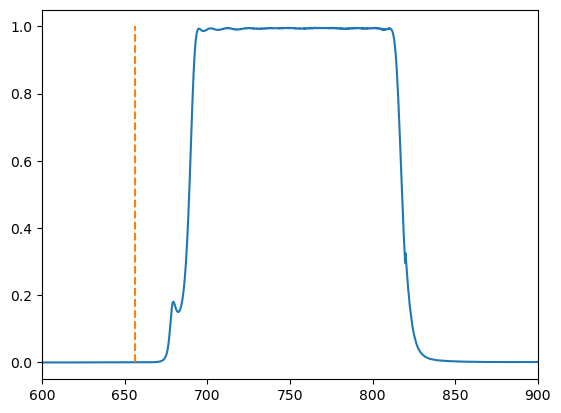

In [34]:
# no Halpha contamination in i' filter
plt.plot(wav_i, resp_i)
plt.xlim(600,900)
plt.vlines(x=656.28, ymax=1.0, ymin=0, linestyles="--", color="tab:orange")

## Conversion Factors for Translating between the used energy band as a function of Temperature

In [35]:
#### Energy in Filters

import astropy.constants as cs
from scipy import integrate 

# integration function using trapzoidal rule
def energy_bol(nu, T):
    y1 = blackbody_nu_bol(nu, T) 
    return integrate.trapezoid(y1, x=nu)

# blackbody model frequency
def blackbody_nu_bol(nu, T):
    x = cs.h * nu / (cs.k_B * T)
    with np.errstate(over="ignore"):
        b = 2 * cs.h * nu**3 / (cs.c**2 * np.expm1(x))
    return b

# defining integral from 0-> "infinity"
nu_bol = np.arange(0.1,20000,1)  
nu_bol = nu_bol*1e12 * 1/u.s #bolometric frequency grid i Hz 

# calculate the conversion factors for translating between different photometric filters
conversion_constants, conversion_constants_i, conversion_constants_v = [], [], [] 
for t in temperatures:
    conversion_constants.append(blackbody_filter(nu_tess, t,resp_tess)/energy_bol(nu_bol, t)) 
    conversion_constants_i.append(blackbody_filter(nu_i, t,resp_i)/energy_bol(nu_bol, t)) 
    conversion_constants_v.append(blackbody_filter(nu_v, t,resp_v)/energy_bol(nu_bol, t))


TypeError: only dimensionless scalar quantities can be converted to Python scalars

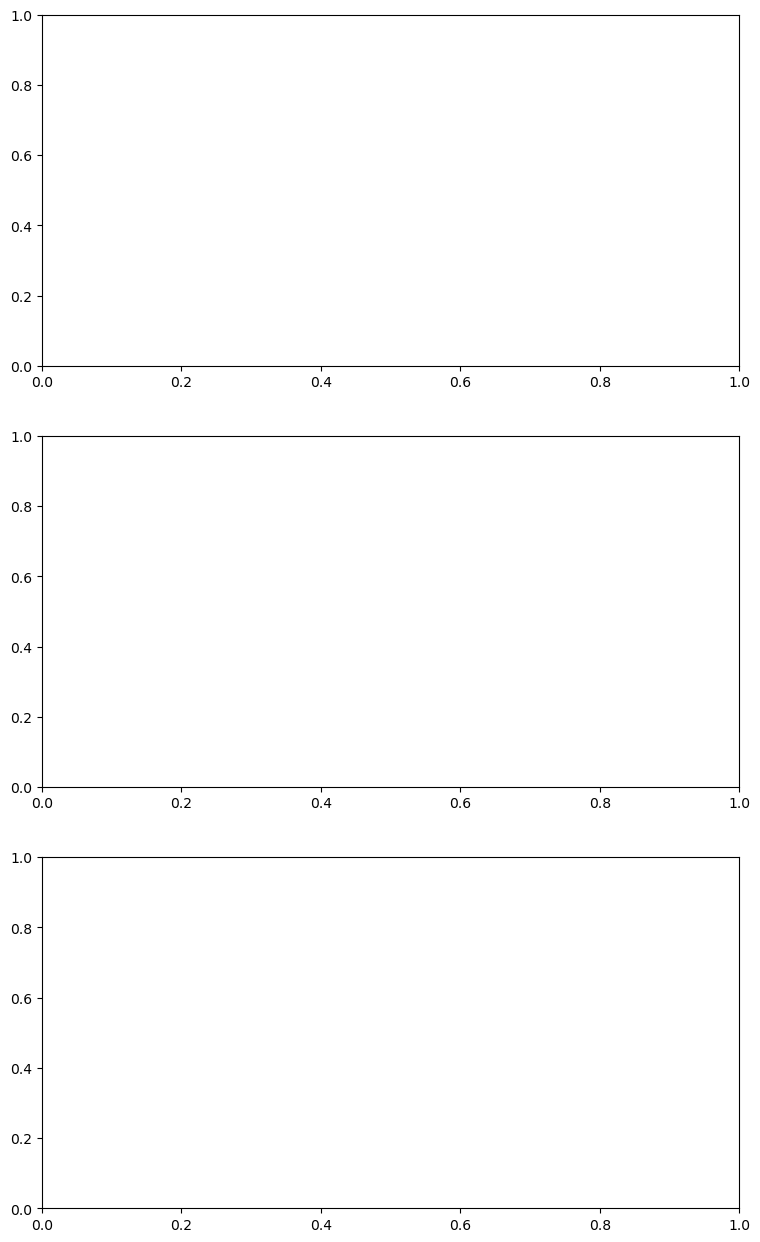

In [38]:
import matplotlib.pyplot as plt 

fig, axes = plt.subplots(ncols=1, nrows=3, figsize=(9,15.5))

axes[0].plot(temperatures, conversion_constants)
axes[0].set_xlabel("Flare Temperature (K)")
axes[0].set_ylabel(r"$c_{TESS/bol} = L_{TESS}/L_{bol}$")

axes[1].plot(temperatures, conversion_constants_i)
axes[1].set_xlabel("Flare Temperature (K)")
axes[1].set_ylabel(r"$c_{i/bol} =L_{i}/L_{bol}$")

axes[2].plot(temperatures, conversion_constants_v)
axes[2].set_xlabel("Flare Temperature (K)")
axes[2].set_ylabel(r"$c_{v/bol} =L_{v}/L_{bol}$")

## Plot Blackbody Flare in different filters

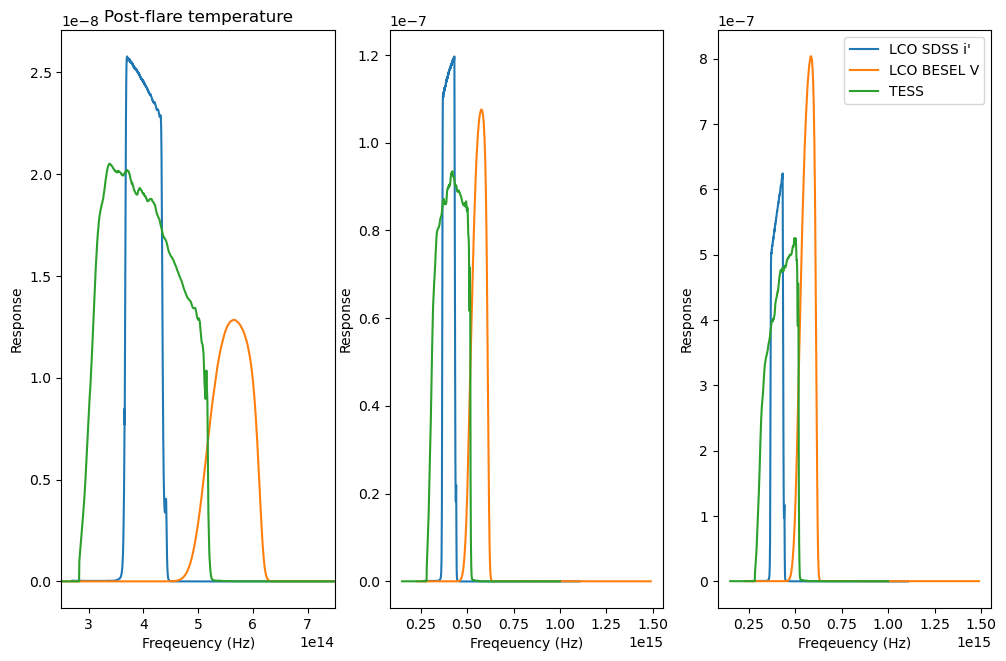

In [37]:
# calculate frequency

# plot bb with 5350 K in different filter and 8950 and 19550
fig, ax = plt.subplots(ncols=3, nrows=1, figsize=(12, 7.5))

# post flare temperature
ax[0].plot(nu_i, blackbody_nu(nu_i, temp_post, resp_i), label = "LCO SDSS i'")
ax[0].plot(nu_v, blackbody_nu(nu_v, temp_post, resp_v), label = "LCO BESEL V")
ax[0].plot(nu_tess, blackbody_nu(nu_tess, temp_post, resp_tess), label = "TESS")
ax[0].set_xlabel("Freqeuency (Hz)")
ax[0].set_ylabel("Response")
ax[0].set_xlim([0.25e15,0.75e15])
ax[0].set_title("Post-flare temperature")

# peak temperature
ax[1].plot(nu_i, blackbody_nu(nu_i, temp_peak, resp_i), label = "LCO SDSS i'")
ax[1].plot(nu_v, blackbody_nu(nu_v, temp_peak, resp_v), label = "LCO BESEL V")
ax[1].plot(nu_tess, blackbody_nu(nu_tess, temp_peak, resp_tess), label = "TESS")
ax[1].set_xlabel("Freqeuency (Hz)")
ax[1].set_ylabel("Response")

# fictive 20000 K
ax[2].plot(nu_i, blackbody_nu(nu_i, 19550*u.K, resp_i), label = "LCO SDSS i'")
ax[2].plot(nu_v, blackbody_nu(nu_v, 19500*u.K, resp_v), label = "LCO BESEL V")
ax[2].plot(nu_tess, blackbody_nu(nu_tess, 19550*u.K, resp_tess), label = "TESS")
ax[2].set_xlabel("Freqeuency (Hz)")
ax[2].set_ylabel("Response")

plt.legend()